# OULAD — model

Bu defter, riskin dersin bağlamına göre değişip değişmediğini ve ders bağlamının öğrenci düzeyindeki tahmine taşınıp taşınmadığını inceler. Hesaplar `data_science` paketindeki fonksiyonlardan gelir. Model, metrik ve grafik burada yazılmaz.


## Soru

Risk, dersin bağlamına göre değişir mi? Ders bağlamı öğrenci düzeyindeki tahmine taşınır mı? Eğitimde hiç görülmeyen bir derste aynı özellikler kullanılır mı?


## Tasarım

Özellik setleri şunlardır.

`GENERAL` kesim gününe kadar ödev ve sanal öğrenme etkinliği ile kayıt gününü taşır. Etkinlik türüne göre tıklama sütunları da girer. Modül kimliği ve geçmiş sunum yoktur.

`GENERAL_MODULE` aynı sütunlara modül kodunu ekler.

`HISTORY` genel sütunlara önceki sunumların modül risk oranını, yuva notunu, yuva teslim oranını, notun geçmiş yuvaya göre farkını ve geçmişin varlığını ekler.

`HISTORY_SLOT` genel sütunlara yuva notunu, yuva teslim oranını, notun geçmiş yuvaya göre farkını ve geçmişin varlığını ekler. Modül risk oranı bu sette yoktur.

`GENERAL_REL` ham değerlerin yerine, aynı modül sunumu içindeki yüzdelik sırayı kullanır. Sıralar not, teslim oranı, tıklama, aktif gün, son etkinliğe yakınlık ve gecikme içindir. Kayıt günü yanında durur. Modül kimliği yoktur. Sıra hesaplanırken risk etiketi okunmaz.

Model türleri `logreg` ve `hgb`.

Ayar, train bölümünün ilk sunumunda eğitilir. Seçim, sonraki sunumun log loss değerine bakar. Seçilen ayar train bölümünün tamamında yeniden oturtulur. Test sunumu bir kez, sonda değerlendirilir. Aralıklar modül içinde sınıfa göre tabakalı bootstrap örneklemlerinden gelir.

`HISTORY_SLOT` ve `GENERAL_REL` ilk test sonuçları görüldükten sonra eklenmiştir. İkisi keşifseldir. Test dondurulmuştur ve doğrulama dönemi ayrıca raporlanır.

Aşağıdaki hücre sunumları, sete giren sütunları ve seçilen ayarları basar.


In [ ]:
from pathlib import Path
import base64
import html
import json
import sys

import numpy as np
import pandas as pd
from IPython.display import HTML, Markdown, display

ROOT = Path.cwd().resolve()
if not (ROOT / "data_science").is_dir():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from data_science.oulad import PROCESSED_OULAD_DIR
from data_science.oulad.dataset import FEATURES_NAME
from data_science.oulad.explain import build_report
from data_science.oulad.figures import write_figures
from data_science.oulad.model import (
    FIT_PRESENTATION,
    MODEL_NAMES,
    SET_NAMES,
    TEST_PRESENTATION,
    VAL_PRESENTATION,
    compare_models,
    feature_columns,
)
from data_science.oulad.model_tables import (
    base_rate_table,
    presentation_counts,
    train_hist_rate_summary,
)
from data_science.oulad.relative import add_relative_features
from data_science.oulad.rule import compare_rule

LANG = "tr"


def dump_json(path, payload):
    def convert(value):
        if isinstance(value, dict):
            return {str(key): convert(item) for key, item in value.items()}
        if isinstance(value, (list, tuple)):
            return [convert(item) for item in value]
        if isinstance(value, np.ndarray):
            return convert(value.tolist())
        if isinstance(value, np.floating):
            value = float(value)
        if isinstance(value, float):
            if np.isnan(value):
                return None
            return float(value)
        if isinstance(value, (np.integer, int)) and not isinstance(value, bool):
            return int(value)
        return value

    Path(path).write_text(
        json.dumps(convert(payload), indent=2, ensure_ascii=False) + "\n",
        encoding="utf-8",
    )


def format_estimate(value):
    return f"{float(value):.6f}"


def format_interval(item):
    return (
        f"{format_estimate(item['estimate'])} "
        f"[{format_estimate(item['low'])}, {format_estimate(item['high'])}]"
    )


def show_table(frame):
    missing = [column for column in ("n", "n_positive") if column not in frame.columns]
    if missing:
        raise ValueError(missing)
    print(
        frame.to_string(
            index=False,
            max_colwidth=None,
            float_format=lambda value: f"{float(value):.6f}",
        )
    )


def show_figure(stem):
    spec = next(item for item in catalog if item["dosya"] == stem)
    alt = spec[f"alt_{LANG}"]
    encoded = base64.b64encode((FIG_DIR / f"{stem}_{LANG}.png").read_bytes()).decode("ascii")
    display(
        HTML(
            f'<img alt="{html.escape(alt, quote=True)}" '
            f'src="data:image/png;base64,{encoded}">'
        )
    )
    display(Markdown(alt))


frame = pd.read_parquet(PROCESSED_OULAD_DIR / FEATURES_NAME, engine="pyarrow")
report, _predictions = compare_models(frame)
del _predictions
params = dict(report["selected_params"]["GENERAL"]["hgb"]["params"])
explain = build_report(frame, params)
rule_report = compare_rule(frame, params)

FIG_DIR = ROOT / "notebooks" / f"_figtmp_{LANG}"
FIG_DIR.mkdir(parents=True, exist_ok=True)
for child in FIG_DIR.iterdir():
    if child.is_file():
        child.unlink()
dump_json(FIG_DIR / "model_metrics.json", report)
dump_json(FIG_DIR / "explain.json", explain)
write_figures(FIG_DIR / "model_metrics.json", FIG_DIR / "explain.json", FIG_DIR)
catalog = json.loads((FIG_DIR / "figures.json").read_text(encoding="utf-8"))

TEST_N = int(sum(row["n"] for row in report["modules"]["rows"]))
TEST_N_POSITIVE = int(sum(row["n_positive"] for row in report["modules"]["rows"]))
_validation_modules = [
    row for row in report["validation"]["modules"]["rows"] if row["set"] == "GENERAL"
]
VAL_N = int(sum(row["n"] for row in _validation_modules))
VAL_N_POSITIVE = int(sum(row["n_positive"] for row in _validation_modules))
SELECTED = report["modules"]["model"]


In [2]:
show_table(presentation_counts(frame))
print(f"fit_presentation={FIT_PRESENTATION}")
print(f"validation_presentation={VAL_PRESENTATION}")
print(f"test_presentation={TEST_PRESENTATION}")

described = add_relative_features(frame)
rows = []
sample_n = int(len(described))
sample_positive = int((described["at_risk"] == 1).sum())
for set_name in SET_NAMES:
    for column in feature_columns(set_name, list(described.columns)):
        rows.append(
            {
                "set": set_name,
                "column": column,
                "n": sample_n,
                "n_positive": sample_positive,
            }
        )
show_table(pd.DataFrame(rows))

rows = []
for set_name in SET_NAMES:
    for model_name in MODEL_NAMES:
        chosen = report["selected_params"][set_name][model_name]
        chosen_params = chosen["params"]
        rows.append(
            {
                "set": set_name,
                "model": model_name,
                "scope": "validation",
                "n": VAL_N,
                "n_positive": VAL_N_POSITIVE,
                "val_log_loss": chosen["val_log_loss"],
                "params": ",".join(f"{key}={chosen_params[key]}" for key in chosen_params),
            }
        )
show_table(pd.DataFrame(rows))


code_presentation   split    n  n_positive
            2013B history 3927        1832
            2013J   train 7446        2971
            2014B   train 6193        2835
            2014J    test 8837        3380
fit_presentation=2013J
validation_presentation=2014B
test_presentation=2014J
           set                column     n  n_positive
       GENERAL            n_expected 26403       11018
       GENERAL           n_submitted 26403       11018
       GENERAL         n_unsubmitted 26403       11018
       GENERAL            score_mean 26403       11018
       GENERAL   score_weighted_mean 26403       11018
       GENERAL            delay_mean 26403       11018
       GENERAL              n_banked 26403       11018
       GENERAL            vle_clicks 26403       11018
       GENERAL       vle_active_days 26403       11018
       GENERAL    vle_days_to_cutoff 26403       11018
       GENERAL     vle_click_forumng 26403       11018
       GENERAL     vle_click_subpage 26403      

## Test

Test bölümünün metrikleri ve eşli farklar basılır. Eşli fark, aynı bootstrap örneklemlerinde sol setten sağ setin çıkarılmasıdır.


In [3]:
rows = []
for set_name in SET_NAMES:
    for model_name in MODEL_NAMES:
        metrics = report["test_metrics"][set_name][model_name]
        for name in metrics:
            item = metrics[name]
            rows.append(
                {
                    "set": set_name,
                    "model": model_name,
                    "metric": name,
                    "estimate": item["estimate"],
                    "low": item["low"],
                    "high": item["high"],
                    "n": TEST_N,
                    "n_positive": TEST_N_POSITIVE,
                }
            )
show_table(pd.DataFrame(rows))

rows = []
for model_name in report["paired_differences"]:
    for contrast in report["paired_differences"][model_name]:
        metrics = report["paired_differences"][model_name][contrast]
        for name in metrics:
            item = metrics[name]
            rows.append(
                {
                    "model": model_name,
                    "contrast": contrast,
                    "metric": name,
                    "estimate": item["estimate"],
                    "low": item["low"],
                    "high": item["high"],
                    "n": TEST_N,
                    "n_positive": TEST_N_POSITIVE,
                }
            )
show_table(pd.DataFrame(rows))


           set  model          metric  estimate      low     high    n  n_positive
       GENERAL logreg         roc_auc  0.786201 0.777361 0.795262 8837        3380
       GENERAL logreg          pr_auc  0.721939 0.710193 0.733707 8837        3380
       GENERAL logreg           brier  0.178800 0.174987 0.182726 8837        3380
       GENERAL logreg        log_loss  0.533769 0.523880 0.543789 8837        3380
       GENERAL logreg precision_at_20  0.782117 0.765139 0.798529 8837        3380
       GENERAL logreg    recall_at_20  0.408876 0.400000 0.417456 8837        3380
       GENERAL    hgb         roc_auc  0.792249 0.783173 0.801196 8837        3380
       GENERAL    hgb          pr_auc  0.738202 0.725992 0.749257 8837        3380
       GENERAL    hgb           brier  0.177486 0.173421 0.181721 8837        3380
       GENERAL    hgb        log_loss  0.529290 0.519176 0.539796 8837        3380
       GENERAL    hgb precision_at_20  0.797397 0.780405 0.815507 8837        3380
    

## İki dönem

Grafik, setlerin doğrulama ve test ROC AUC değerini birleştirir. Tablo aynı değerleri yan yana koyar. Testte en yüksek ROC AUC değerine sahip set, doğrulamada daha geridedir.



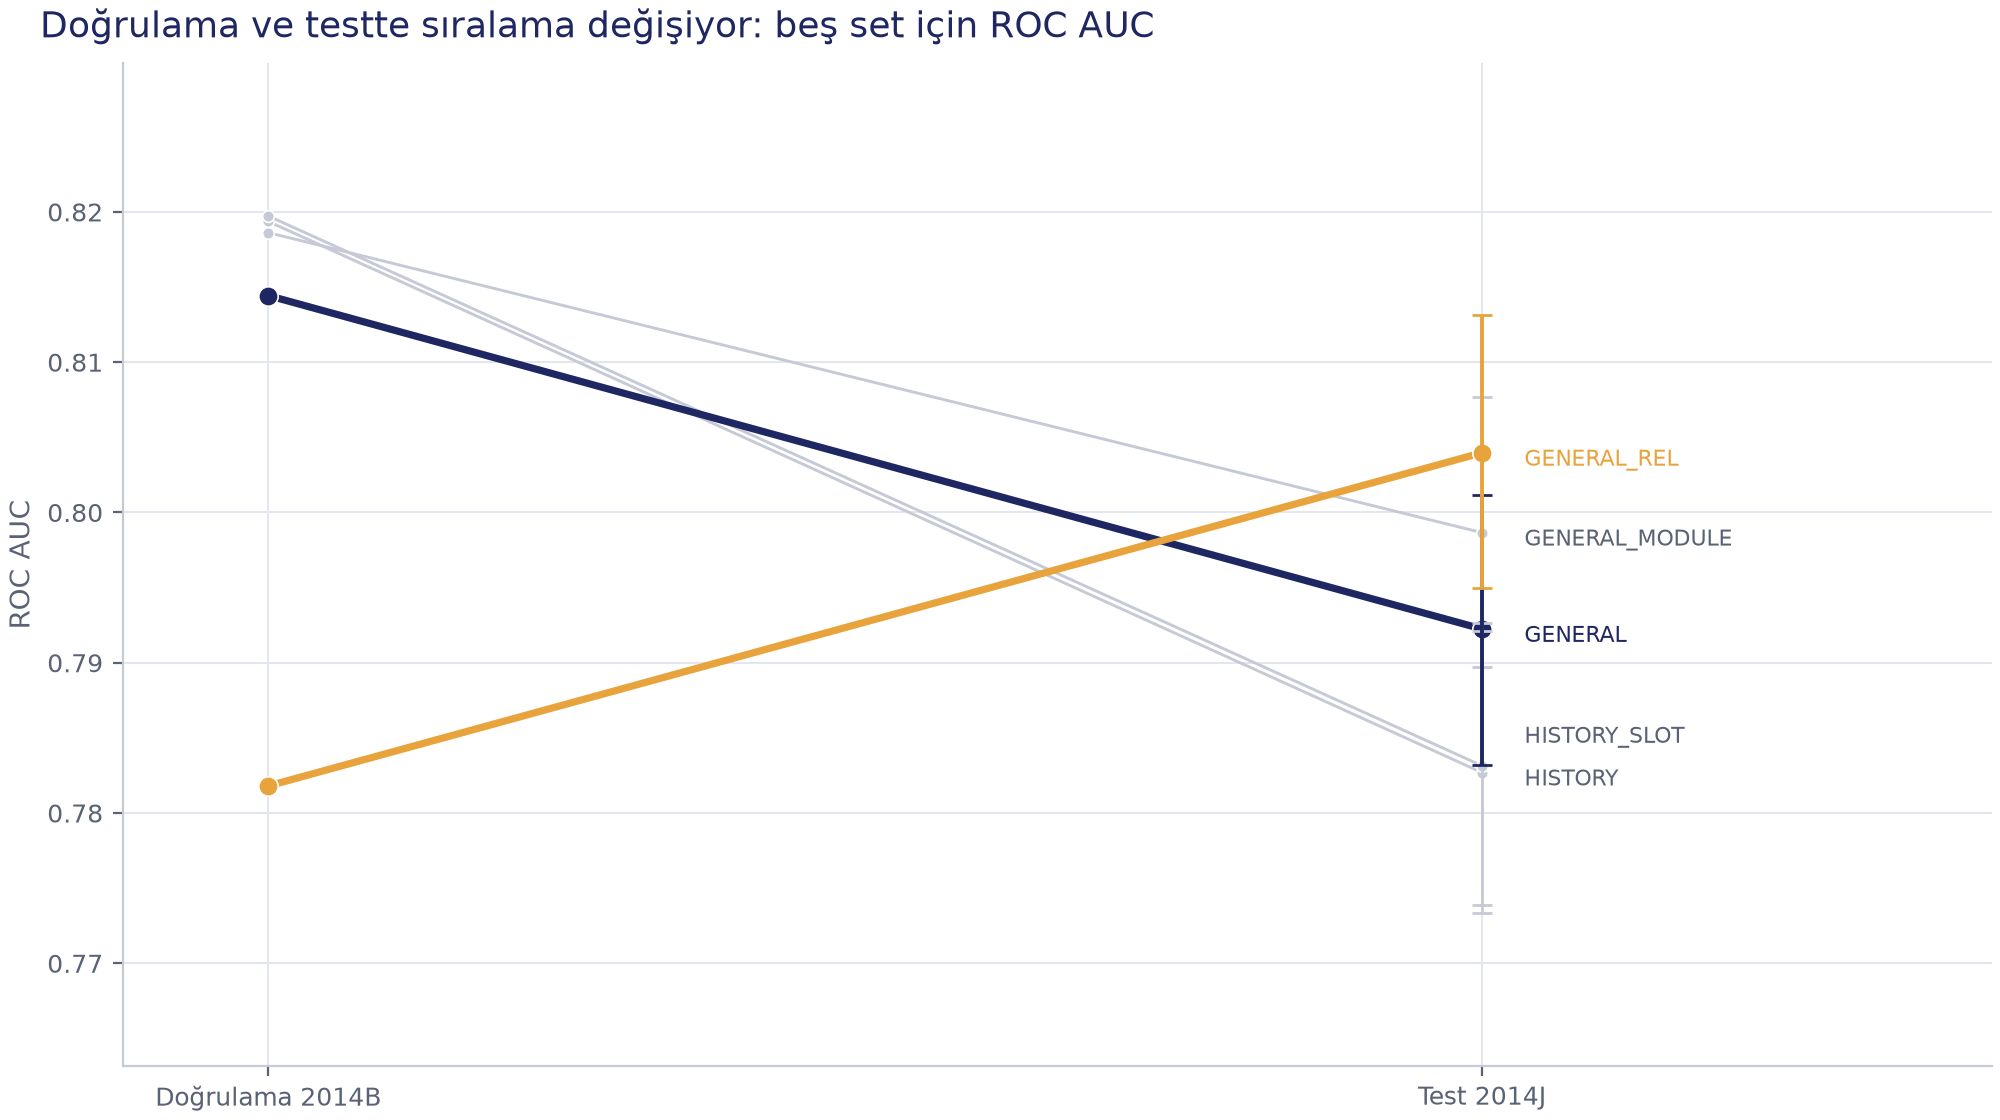

Her çizgi bir özellik setinin doğrulama ve test ROC AUC değerini birleştirir. Kalın çizgiler genel ve göreli genel setlerdir; diğerleri incedir. Yalnızca test noktasında yüzde doksan beş aralık vardır. Doğrulama noktasında aralık yoktur.

           set model    n  n_positive  validation_n  validation_n_positive  validation_roc_auc  test_roc_auc  test_roc_auc_low  test_roc_auc_high
   GENERAL_REL   hgb 8837        3380          6193                   2835            0.781802      0.803975          0.794995           0.813152
GENERAL_MODULE   hgb 8837        3380          6193                   2835            0.818626      0.798659          0.789696           0.807681
       GENERAL   hgb 8837        3380          6193                   2835            0.814433      0.792249          0.783173           0.801196
  HISTORY_SLOT   hgb 8837        3380          6193                   2835            0.819730      0.783149          0.773903           0.792661
       HISTORY   hgb 8837        3380          6193                   2835            0.819369      0.782694          0.773355           0.792140


In [4]:
show_figure("fig01_roc_egim")

rows = []
for set_name in SET_NAMES:
    validation = next(
        row["roc_auc"]
        for row in report["validation"]["rows"]
        if row["set"] == set_name and row["model"] == "hgb"
    )
    test = report["test_metrics"][set_name]["hgb"]["roc_auc"]
    rows.append(
        {
            "set": set_name,
            "model": "hgb",
            "n": TEST_N,
            "n_positive": TEST_N_POSITIVE,
            "validation_n": VAL_N,
            "validation_n_positive": VAL_N_POSITIVE,
            "validation_roc_auc": validation,
            "test_roc_auc": test["estimate"],
            "test_roc_auc_low": test["low"],
            "test_roc_auc_high": test["high"],
        }
    )
table = pd.DataFrame(rows)
table = table.sort_values(["test_roc_auc", "set"], ascending=[False, True], kind="mergesort")
show_table(table.reset_index(drop=True))


## Taban oran

Grafik, test döneminde modül bazında gerçek oran ile ortalama tahmini birlikte gösterir. Tablolar, geçmiş modül oranını bu dönemin oranının yanına koyar ve train bölümünde `hist_module_risk_rate` sütununun farklı değer sayısını basar. Modül içi ROC AUC ayrı bir tablodadır.



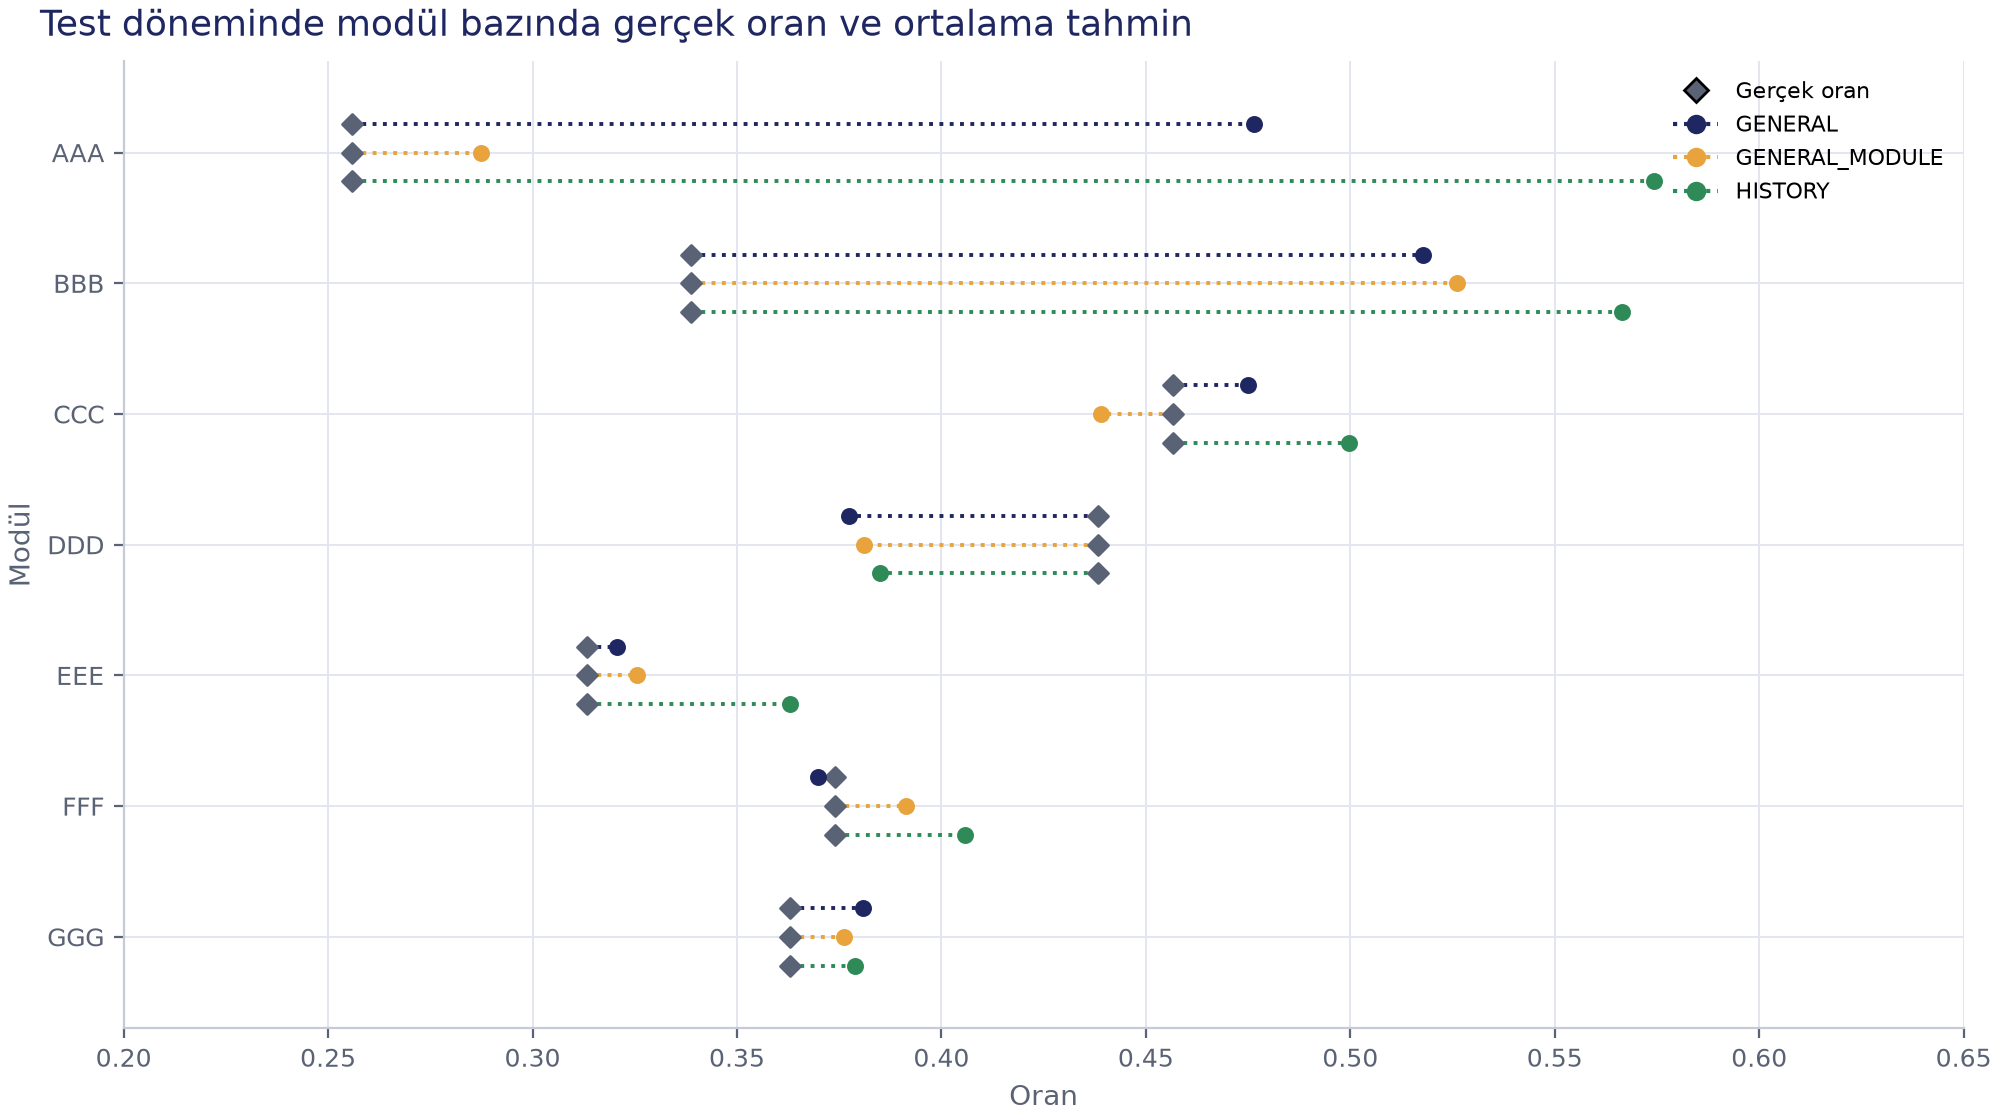

Her satır bir modüldür. Noktalar gerçek oranı ve genel, modül bilgili ve geçmişli setlerin ortalama tahminini gösterir. Noktalı çizgiler aynı modüldeki değerleri birleştirir.

split     n  n_positive  n_distinct_hist_module_risk_rate
train 13639        5806                                 8
code_module    n  n_positive  hist_module_risk_rate  positive_rate  test_n_distinct_hist_module_risk_rate  train_n  train_n_positive  train_n_distinct_hist_module_risk_rate
        AAA  340          87               0.234160       0.255882                                      1      363                85                                       0
        BBB 1742         590               0.419973       0.338691                                      1     3031              1232                                       2
        CCC 1868         853               0.509615       0.456638                                      1     1352               689                                       0
        DDD 1410         618               0.496538       0.438298                                      1     2534              1226                                       2
        EEE  996   

In [5]:
show_figure("fig02_oran_kaymasi")

show_table(train_hist_rate_summary(frame))
show_table(base_rate_table(frame))

rows = []
for row in report["modules"]["rows"]:
    flat = {
        "model": report["modules"]["model"],
        "code_module": row["code_module"],
        "n": row["n"],
        "n_positive": row["n_positive"],
    }
    for set_name in SET_NAMES:
        value = row["roc_auc"][set_name]
        flat[set_name] = float("nan") if value is None else value
    rows.append(flat)
show_table(pd.DataFrame(rows))


## Görülmemiş ders

Grafik, eğitimde hiç görülmeyen ders için ortalama tahmin ile gerçek oranı birlikte gösterir. LOMO, seçilen `hgb` ayarını yenilemeden her modülü eğitimden çıkarır ve test sunumunda o modülü değerlendirir. Son tablolar, kesim gününe kadar beklenen ödevi ve gözlenen notu sayar. GGG satırlarında beklenen ödev ve gözlenen not yoktur.



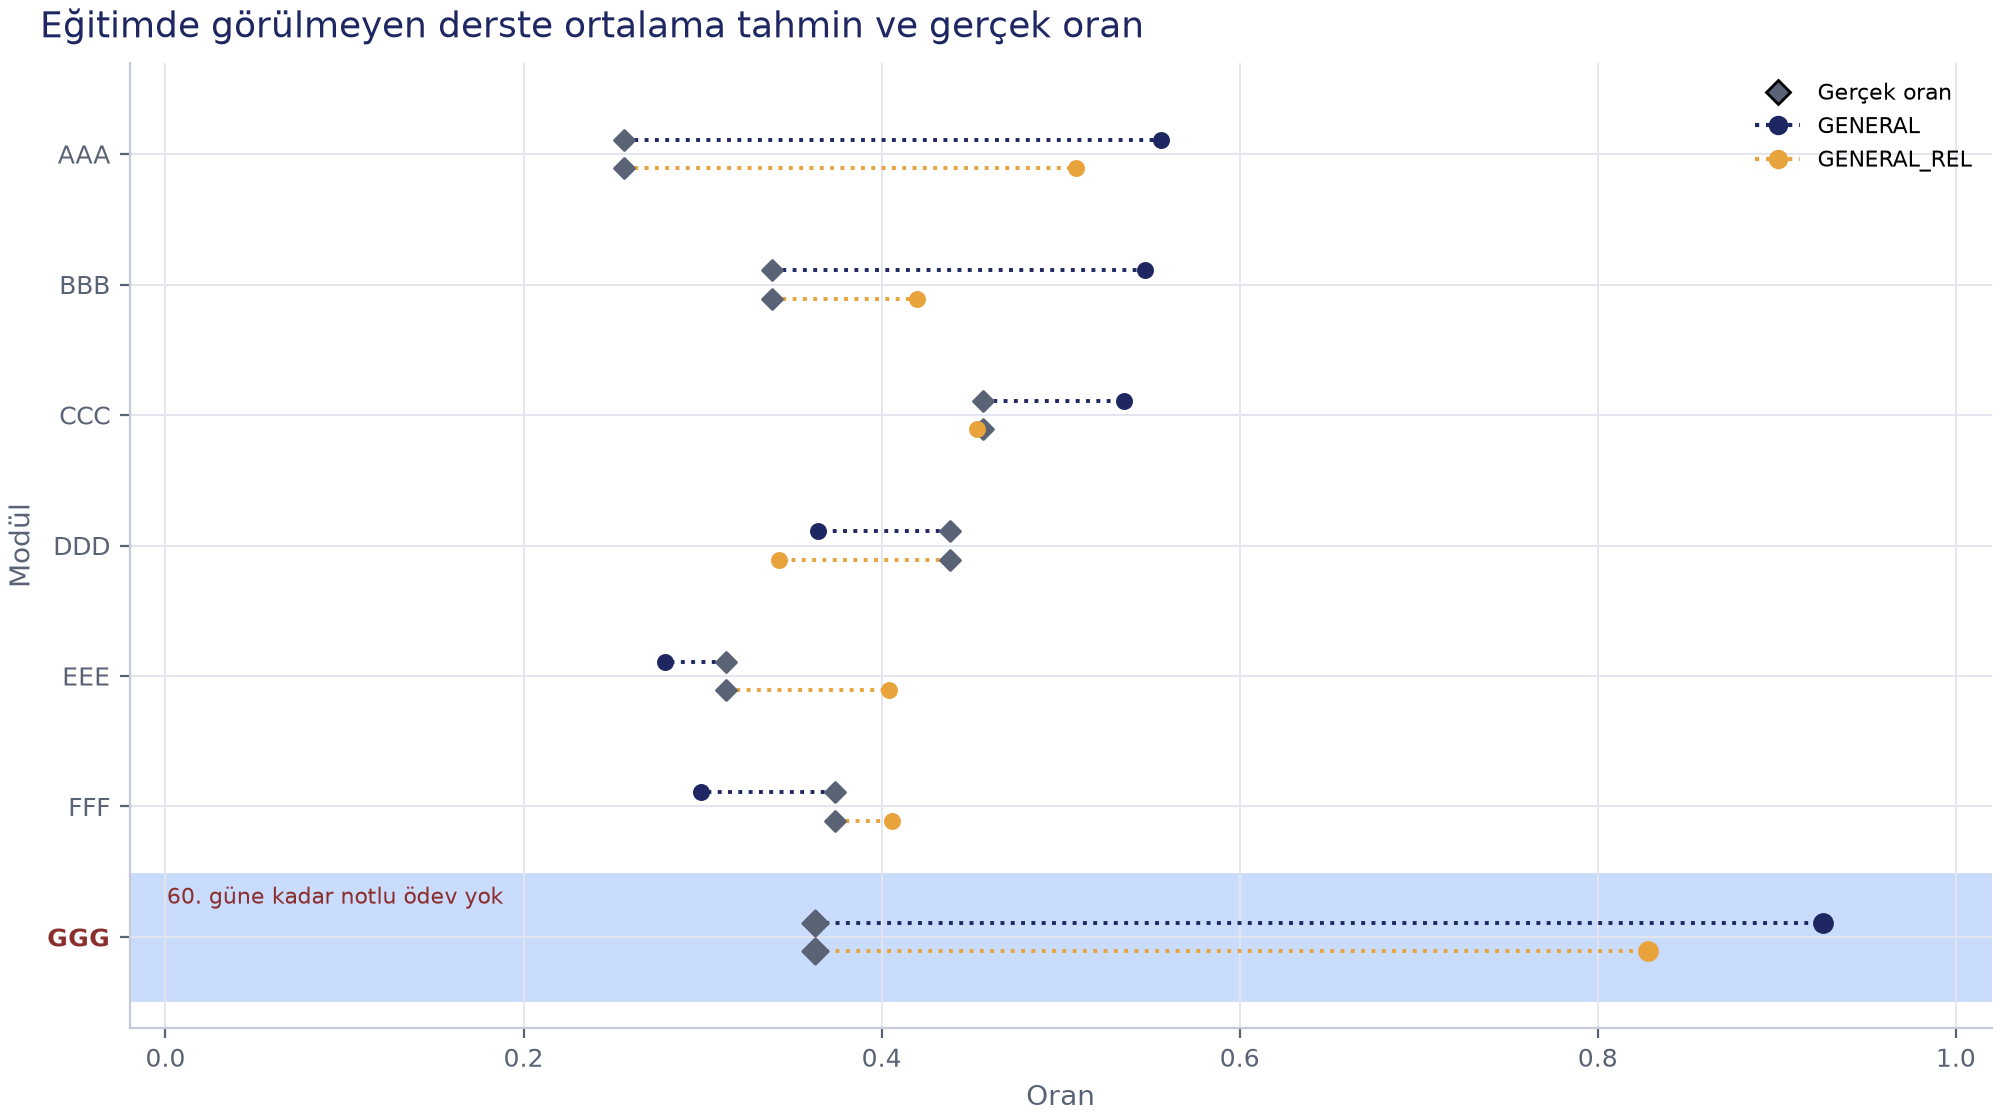

Her satır, eğitimde hiç görülmeyen bir derstir. Noktalar gerçek oranı ve genel ile göreli genel setlerin ortalama tahminini gösterir. Vurgulu satır, kesim gününe kadar notlu ödevi olmayan derstir.

code_module            set    n  n_positive  roc_auc    brier  mean_prediction  positive_rate
        AAA        GENERAL  340          87 0.771750 0.253326         0.556196       0.255882
        AAA GENERAL_MODULE  340          87 0.777111 0.244049         0.544154       0.255882
        AAA    GENERAL_REL  340          87 0.777429 0.232560         0.508447       0.255882
        AAA        HISTORY  340          87 0.774613 0.270995         0.583346       0.255882
        BBB        GENERAL 1742         590 0.764413 0.227328         0.547350       0.338691
        BBB GENERAL_MODULE 1742         590 0.768787 0.231525         0.559707       0.338691
        BBB    GENERAL_REL 1742         590 0.769284 0.179512         0.419670       0.338691
        BBB        HISTORY 1742         590 0.743685 0.258962         0.585761       0.338691
        CCC        GENERAL 1868         853 0.797069 0.191358         0.535339       0.456638
        CCC GENERAL_MODULE 1868         853 0.796251 0.19220

In [6]:
show_figure("fig03_gorulmemis_ders")

show_table(pd.DataFrame(report["lomo"]["rows"]))
rows = []
for set_name, item in report["lomo"]["mean"].items():
    rows.append(
        {
            "set": set_name,
            "n": item["n"],
            "n_positive": item["n_positive"],
            "roc_auc": float("nan") if item["roc_auc"] is None else item["roc_auc"],
            "brier": float("nan") if item["brier"] is None else item["brier"],
        }
    )
show_table(pd.DataFrame(rows))

rows = []
for name, part in frame.groupby(frame["code_module"].astype(str), sort=True):
    expected = pd.to_numeric(part["n_expected"], errors="coerce")
    score = pd.to_numeric(part["score_mean"], errors="coerce")
    rows.append(
        {
            "code_module": str(name),
            "n": int(len(part)),
            "n_positive": int((part["at_risk"] == 1).sum()),
            "n_expected_zero": int(expected.fillna(0).eq(0).sum()),
            "n_with_score": int(score.notna().sum()),
        }
    )
show_table(pd.DataFrame(rows))

ggg = frame.loc[frame["code_module"].astype(str).eq("GGG")]
rows = []
for presentation, part in ggg.groupby(ggg["code_presentation"].astype(str), sort=True):
    expected = pd.to_numeric(part["n_expected"], errors="coerce")
    score = pd.to_numeric(part["score_mean"], errors="coerce")
    rows.append(
        {
            "code_module": "GGG",
            "code_presentation": str(presentation),
            "n": int(len(part)),
            "n_positive": int((part["at_risk"] == 1).sum()),
            "n_expected_zero": int(expected.fillna(0).eq(0).sum()),
            "n_with_score": int(score.notna().sum()),
        }
    )
show_table(pd.DataFrame(rows))


## Modelin dayandığı özellikler

Grafik, genel `hgb` modelinin hangi sütunlara dayandığını SHAP ile gösterir. Pozitif SHAP, modelin tahmini riski artırdığı yöndür. Bu yön bir neden değildir.



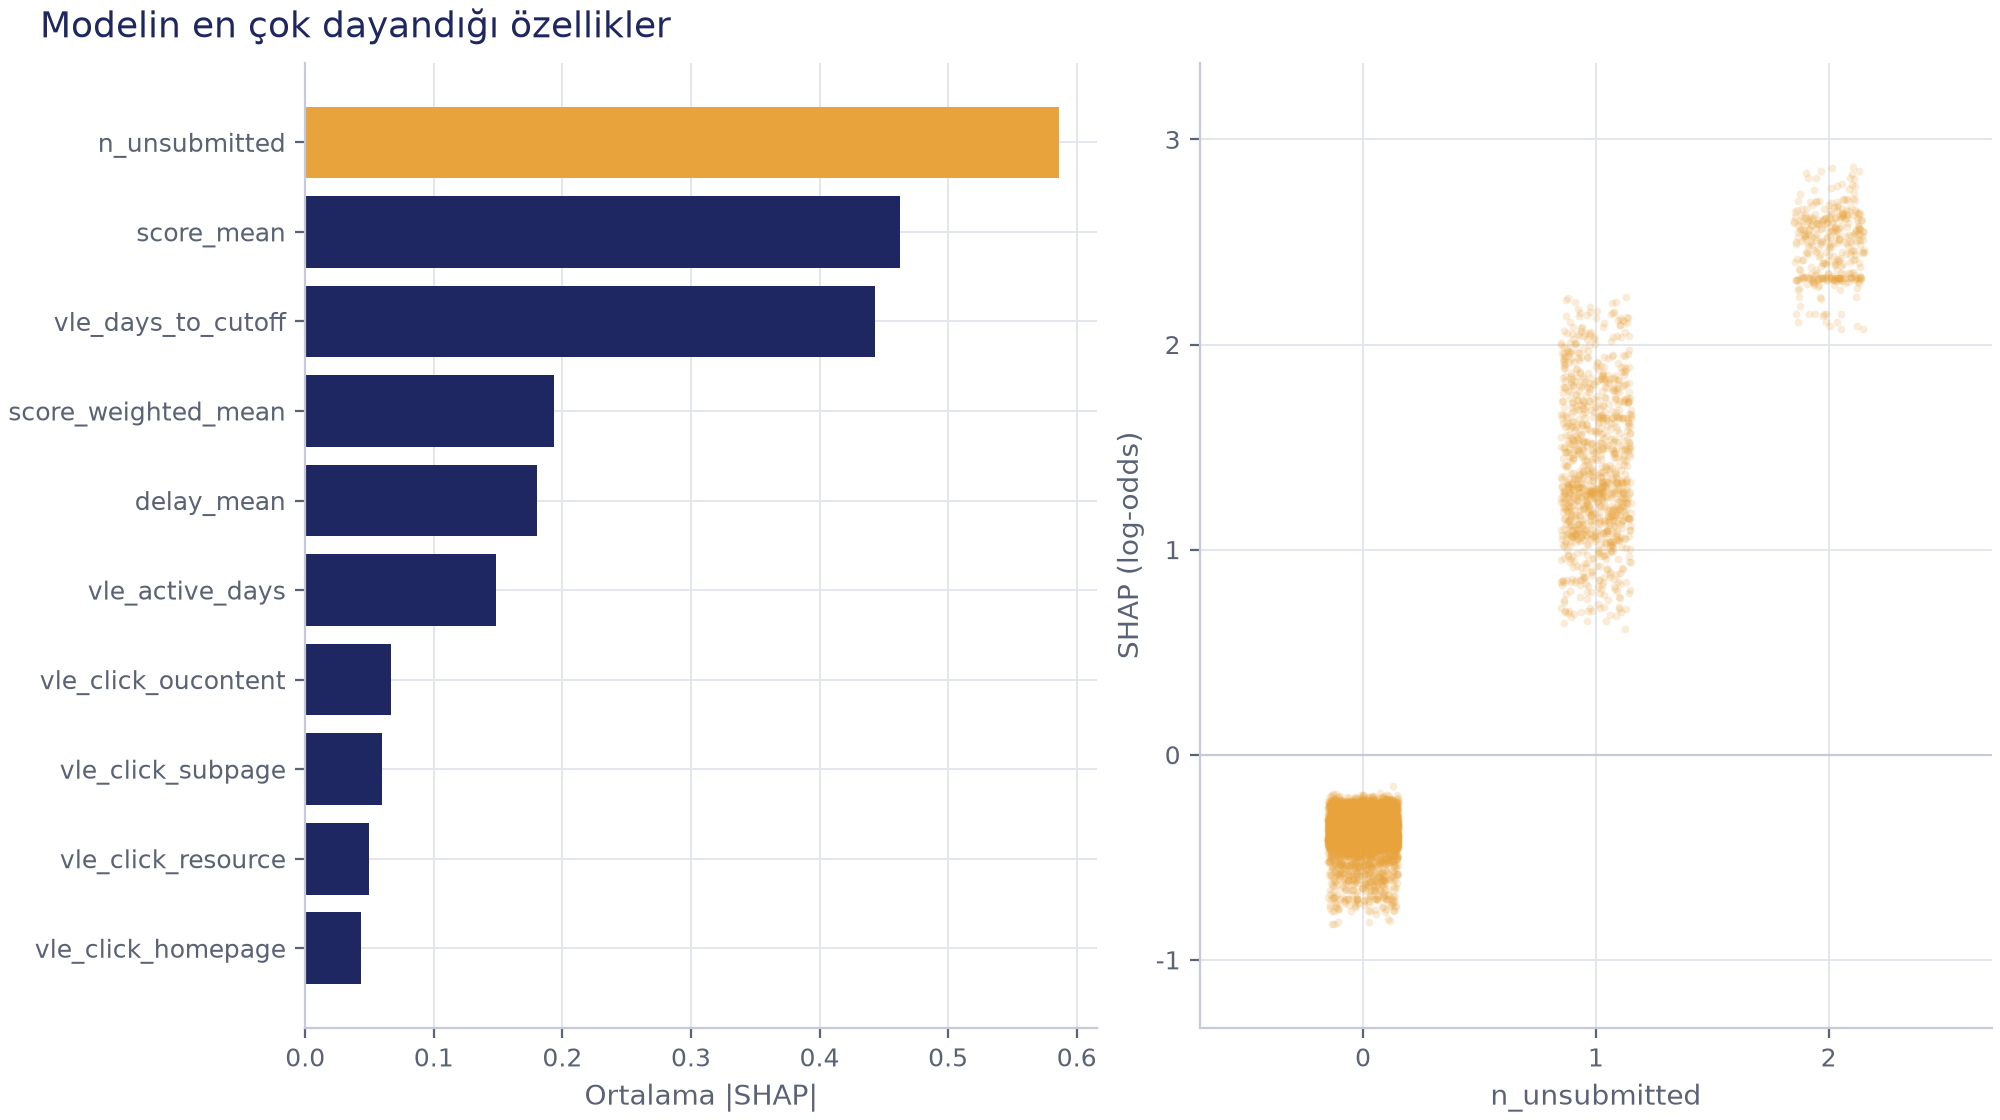

Sol panel özelliklerin ortalama mutlak SHAP değerini karşılaştırır. Sağ panel en yüksek ortalama mutlak değere sahip özelliğin gözlenen değerini SHAP ile birlikte gösterir. Pozitif SHAP, modelin tahmini riski artırdığı yönü gösterir; nedensel bir etki değildir.

    set model             feature  mean_abs_shap    n  n_positive  n_explained
GENERAL   hgb       n_unsubmitted       0.586302 8837        3380         8837
GENERAL   hgb          score_mean       0.462219 8837        3380         8837
GENERAL   hgb  vle_days_to_cutoff       0.443273 8837        3380         8837
GENERAL   hgb score_weighted_mean       0.193407 8837        3380         8837
GENERAL   hgb          delay_mean       0.180594 8837        3380         8837
GENERAL   hgb     vle_active_days       0.148204 8837        3380         8837
GENERAL   hgb vle_click_oucontent       0.066787 8837        3380         8837
GENERAL   hgb   vle_click_subpage       0.059949 8837        3380         8837
GENERAL   hgb  vle_click_resource       0.049387 8837        3380         8837
GENERAL   hgb  vle_click_homepage       0.043570 8837        3380         8837
GENERAL   hgb   date_registration       0.039337 8837        3380         8837
GENERAL   hgb         n_submitted       0.031928 883

In [7]:
show_figure("fig05_shap")

shap = explain["shap"]
rows = []
for item in shap["features"]:
    rows.append(
        {
            "set": shap["set"],
            "model": shap["model"],
            "feature": item["feature"],
            "mean_abs_shap": item["mean_abs_shap"],
            "n": TEST_N,
            "n_positive": TEST_N_POSITIVE,
            "n_explained": int(shap["n_explained"]),
        }
    )
show_table(pd.DataFrame(rows))


## Karar kuralı

Grafik, bayrak oranı değiştikçe kesinliği çizer. Biri öğrencileri birlikte sıralar, diğeri her modülün içinde sıralar. Tablolar aynı eğriyi ve sınıf içi bayrağı basar.



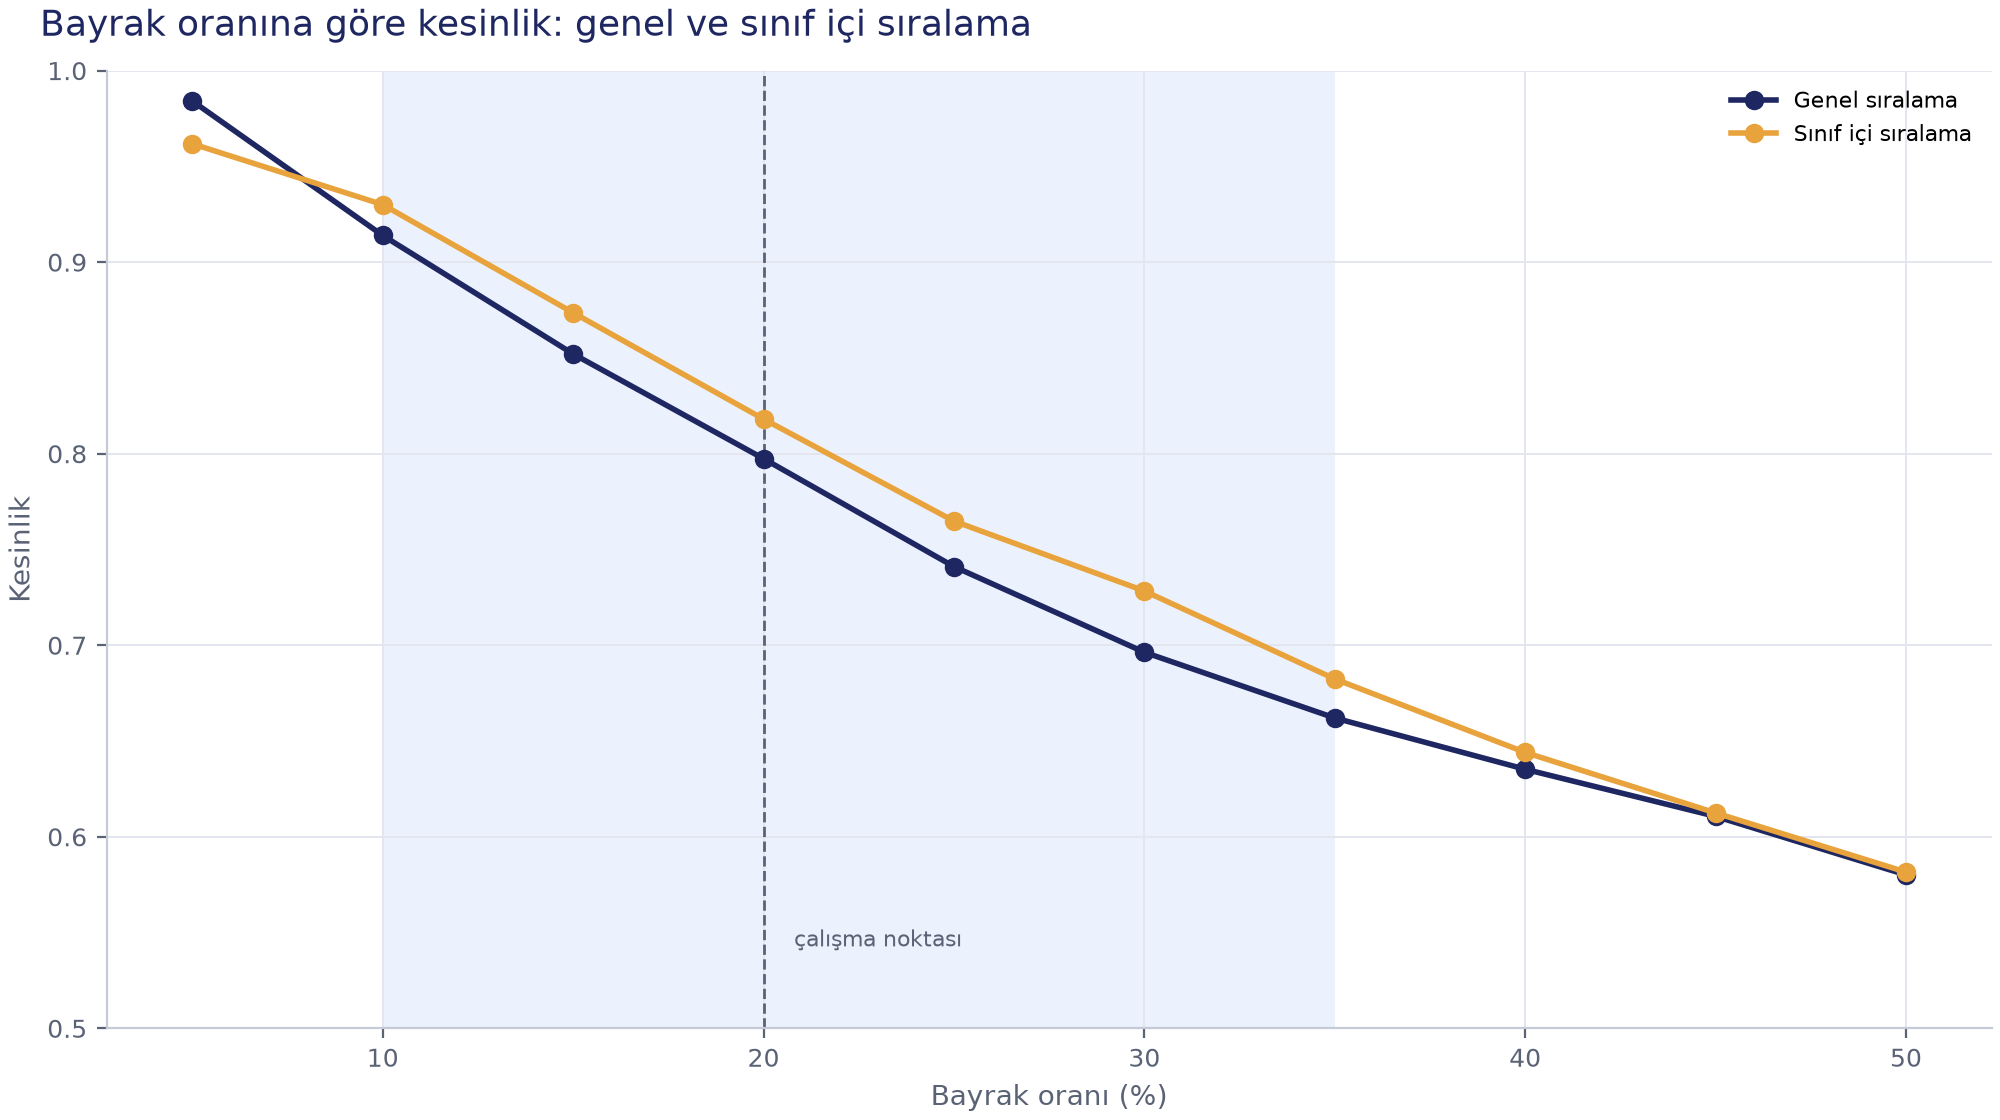

Çizgiler bayrak oranı değiştikçe kesinliği gösterir. Biri öğrencileri birlikte sıralar, diğeri her modülün içinde sıralar. Kesikli çizgi seçilen bayrak oranını, açık bant sınıf içi sıralamanın önde olduğu aralığı gösterir.

    set model presentation  flag_rate       ranking    n  n_positive  n_flagged  n_hit  precision   recall
GENERAL   hgb        2014J   0.050000        global 8837        3380        441    434   0.984127 0.128402
GENERAL   hgb        2014J   0.050000 within_module 8837        3380        445    428   0.961798 0.126627
GENERAL   hgb        2014J   0.100000        global 8837        3380        883    807   0.913930 0.238757
GENERAL   hgb        2014J   0.100000 within_module 8837        3380        886    824   0.930023 0.243787
GENERAL   hgb        2014J   0.150000        global 8837        3380       1325   1129   0.852075 0.334024
GENERAL   hgb        2014J   0.150000 within_module 8837        3380       1329   1161   0.873589 0.343491
GENERAL   hgb        2014J   0.200000        global 8837        3380       1767   1409   0.797397 0.416864
GENERAL   hgb        2014J   0.200000 within_module 8837        3380       1770   1448   0.818079 0.428402
GENERAL   hgb        2014J   0.250000

In [8]:
show_figure("fig04_kapasite")

rows = []
capacity = explain["capacity"]
for row in capacity["rows"]:
    for ranking in ("global", "within_module"):
        item = row[ranking]
        rows.append(
            {
                "set": capacity["set"],
                "model": capacity["model"],
                "presentation": capacity["presentation"],
                "flag_rate": row["flag_rate"],
                "ranking": ranking,
                "n": item["n"],
                "n_positive": item["n_positive"],
                "n_flagged": item["n_flagged"],
                "n_hit": item["n_hit"],
                "precision": item["precision"],
                "recall": item["recall"],
            }
        )
show_table(pd.DataFrame(rows))

rows = []
for row in report["within_module"]["rows"]:
    if row["set"] != "GENERAL":
        continue
    rows.append(
        {
            "model": report["within_module"]["model"],
            "set": row["set"],
            "code_module": row["code_module"],
            "n": row["n"],
            "n_positive": row["n_positive"],
            "n_flagged": row["n_flagged"],
            "n_hit": row["n_hit"],
            "precision": row["precision"],
            "recall": row["recall"],
        }
    )
show_table(pd.DataFrame(rows))
rows = []
for row in report["within_module"]["total"]:
    if row["set"] != "GENERAL":
        continue
    rows.append(
        {
            "model": report["within_module"]["model"],
            "set": row["set"],
            "n": row["n"],
            "n_positive": row["n_positive"],
            "n_flagged": row["n_flagged"],
            "n_hit": row["n_hit"],
            "precision": row["precision"],
            "recall": row["recall"],
        }
    )
show_table(pd.DataFrame(rows))


## Sisteme köprü

Okul sisteminde eğitim etiketi yoktur. Şeffaf kural etiket kullanmaz. Sunum içinde teslim edilmeyen ödev, not ve aktif gün sıralarının ortalamasıdır. Kural ve genel `hgb` modeli aynı uygun öğrencilerde, doğrulama ve test sunumlarında yan yana durur. Aradaki bedel bu tabloda görünür.


In [9]:
rows = []
for item in rule_report["excluded"]:
    mask = frame["code_module"].astype(str).eq(item["code_module"]) & frame[
        "code_presentation"
    ].astype(str).eq(item["code_presentation"])
    part = frame.loc[mask]
    if int(mask.sum()) != int(item["n"]):
        raise ValueError(item["code_module"])
    rows.append(
        {
            "code_module": item["code_module"],
            "code_presentation": item["code_presentation"],
            "n": int(item["n"]),
            "n_positive": int((part["at_risk"] == 1).sum()),
        }
    )
show_table(pd.DataFrame(rows))
show_table(pd.DataFrame(rule_report["total"]))
show_table(pd.DataFrame(rule_report["rows"]))


code_module code_presentation   n  n_positive
        GGG             2014B 790         312
        GGG             2014J 697         253
presentation      method    n  n_positive  n_flagged  n_hit  precision   recall
       2014B        rule 5403        2523       1083    975   0.900277 0.386445
       2014B general_hgb 5403        2523       1083   1012   0.934441 0.401110
       2014J        rule 8140        3127       1630   1283   0.787117 0.410297
       2014J general_hgb 8140        3127       1630   1352   0.829448 0.432363
presentation      method code_module    n  n_positive  n_flagged  n_hit  precision   recall
       2014B        rule         BBB 1248         521        250    210   0.840000 0.403071
       2014B        rule         CCC 1352         689        271    250   0.922509 0.362845
       2014B        rule         DDD  967         488        194    181   0.932990 0.370902
       2014B        rule         EEE  586         229        118    104   0.881356 0.454148
  

## Sınırlılıklar

Veri tek kurumdandır. Fail ve Withdrawn aynı sınıftadır. LOMO satırlarında aralık yoktur. Doğrulama tek dönemdir. Test birden çok kez görülmüştür; bu görme yalnızca değerlendirmedir ve ayarı yenilemez. SHAP bir neden göstermez.


## OZET

Hücre özeti anahtar ve değer satırları olarak basar.


In [10]:
print("OZET")
roc = report["test_metrics"]["GENERAL"][SELECTED]["roc_auc"]
diff = report["paired_differences"][SELECTED]["HISTORY-GENERAL"]["roc_auc"]
rel_validation = next(
    row["roc_auc"]
    for row in report["validation"]["rows"]
    if row["set"] == "GENERAL_REL" and row["model"] == SELECTED
)
rel_test = report["test_metrics"]["GENERAL_REL"][SELECTED]["roc_auc"]
global_precision = report["test_metrics"]["GENERAL"][SELECTED]["precision_at_20"]["estimate"]
within_precision = next(
    row["precision"] for row in report["within_module"]["total"] if row["set"] == "GENERAL"
)
indexed = {(row["presentation"], row["method"]): row for row in rule_report["total"]}
print(f"selected_model={SELECTED}")
print("test_set=GENERAL")
print(f"test_roc_auc={format_interval(roc)}")
print(f"history_minus_general_roc_auc={format_interval(diff)}")
print(f"general_rel_validation_roc_auc={format_estimate(rel_validation)}")
print(f"general_rel_test_roc_auc={format_interval(rel_test)}")
print(f"precision_at_20_global={format_estimate(global_precision)}")
print(f"precision_at_20_within_module={format_estimate(within_precision)}")
for presentation in (VAL_PRESENTATION, TEST_PRESENTATION):
    print(
        f"{presentation}_rule_precision="
        f"{format_estimate(indexed[(presentation, 'rule')]['precision'])}"
    )
    print(
        f"{presentation}_model_precision="
        f"{format_estimate(indexed[(presentation, 'general_hgb')]['precision'])}"
    )


OZET
selected_model=hgb
test_set=GENERAL
test_roc_auc=0.792249 [0.783173, 0.801196]
history_minus_general_roc_auc=-0.009555 [-0.011728, -0.007301]
general_rel_validation_roc_auc=0.781802
general_rel_test_roc_auc=0.803975 [0.794995, 0.813152]
precision_at_20_global=0.797397
precision_at_20_within_module=0.818079
2014B_rule_precision=0.900277
2014B_model_precision=0.934441
2014J_rule_precision=0.787117
2014J_model_precision=0.829448
